# 🔬 Attention U-Net for Skin Lesion Segmentation

**Model:** Attention U-Net (LeeJunHyun implementation)  
**Dataset:** HAM10000  
**Hardware:** Google Colab T4 GPU  

This notebook uses the **official Attention U-Net** implementation that adds attention gates to focus on relevant features.

---

## 🔧 Part 1: Setup & Installation

### Cell 1 — Install Dependencies & Clone Attention U-Net

In [ ]:
# Install required packages
!pip install -q kaggle albumentations opencv-python matplotlib seaborn pandas scikit-learn tqdm

# Clone Attention U-Net repository
!git clone https://github.com/LeeJunHyun/Image_Segmentation.git

# Add to Python path
import sys
sys.path.append('/content/Image_Segmentation')

print("✅ Dependencies installed")
print("✅ Attention U-Net repository cloned")

Cloning into 'Image_Segmentation'...
remote: Enumerating objects: 54, done.
remote: Counting objects: 100% (1/1), done.
remote: Total 54 (delta 0), reused 0 (delta 0), pack-reused 53 (from 3)
Receiving objects: 100% (54/54), 265.65 KiB | 10.63 MiB/s, done.
Resolving deltas: 100% (22/22), done.
✅ Dependencies installed
✅ Attention U-Net repository cloned


### Cell 2 — Set Kaggle Credentials

In [ ]:
# ✅ FILL IN YOUR CREDENTIALS HERE
KAGGLE_USERNAME = "your_kaggle_username"
KAGGLE_KEY      = "your_kaggle_api_key"

import os
os.environ["KAGGLE_USERNAME"] = KAGGLE_USERNAME
os.environ["KAGGLE_KEY"]      = KAGGLE_KEY

print("✅ Kaggle credentials set")

✅ Kaggle credentials set


### Cell 3 — Download HAM10000 Dataset

In [ ]:
!mkdir -p ~/.kaggle
!echo '{"username":"'$KAGGLE_USERNAME'","key":"'$KAGGLE_KEY'"}' > ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

# Download images
!kaggle datasets download -d kmader/skin-cancer-mnist-ham10000 \
    -p /content/ham10000 --unzip

# Download segmentation masks
!kaggle datasets download -d tschandl/ham10000-lesion-segmentations \
    -p /content/ham10000_masks --unzip

print("✅ Dataset downloaded")

Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [02:10<00:00, 42.8MB/s]

Dataset URL: https://www.kaggle.com/datasets/tschandl/ham10000-lesion-segmentations
License(s): Attribution-NonCommercial 4.0 International (CC BY-NC 4.0)
100% 10.3M/10.3M [00:01<00:00, 10.4MB/s]

✅ Dataset downloaded


### Cell 4 — Import Libraries

In [ ]:
import os
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
from sklearn.model_selection import train_test_split
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Import Attention U-Net models
from network import U_Net, R2U_Net, AttU_Net, R2AttU_Net

# Set random seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
print(f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

Device: cuda
GPU: Tesla T4


---
## 📊 Part 2: Data Preparation

### Cell 5 — Match Images with Masks

In [ ]:
# Collect all images
all_images = glob.glob("/content/ham10000/**/*.jpg", recursive=True)

img_dict = {}
for p in all_images:
    name = os.path.basename(p).replace(".jpg", "")
    img_dict[name] = p

print(f"Total images: {len(img_dict)}")

# Collect all masks
all_masks = glob.glob("/content/ham10000_masks/**/*.png", recursive=True)
print(f"Total masks: {len(all_masks)}")

# Match images with masks
pairs = []
for mask_path in all_masks:
    mask_name = os.path.basename(mask_path).replace("_segmentation", "").replace(".png", "")
    if mask_name in img_dict:
        pairs.append((img_dict[mask_name], mask_path))

print(f"\n✅ Matched pairs: {len(pairs)}")

# Show sample
if pairs:
    sample_img, sample_mask = pairs[0]
    print(f"\nSample image: {sample_img}")
    print(f"Sample mask : {sample_mask}")

Total images: 10015
Total masks: 10015

✅ Matched pairs: 10015

Sample image: /content/ham10000/ham10000_images_part_1/ISIC_0025196.jpg
Sample mask : /content/ham10000_masks/HAM10000_segmentations_lesion_tschandl/ISIC_0025196_segmentation.png


### Cell 6 — Visualize Samples

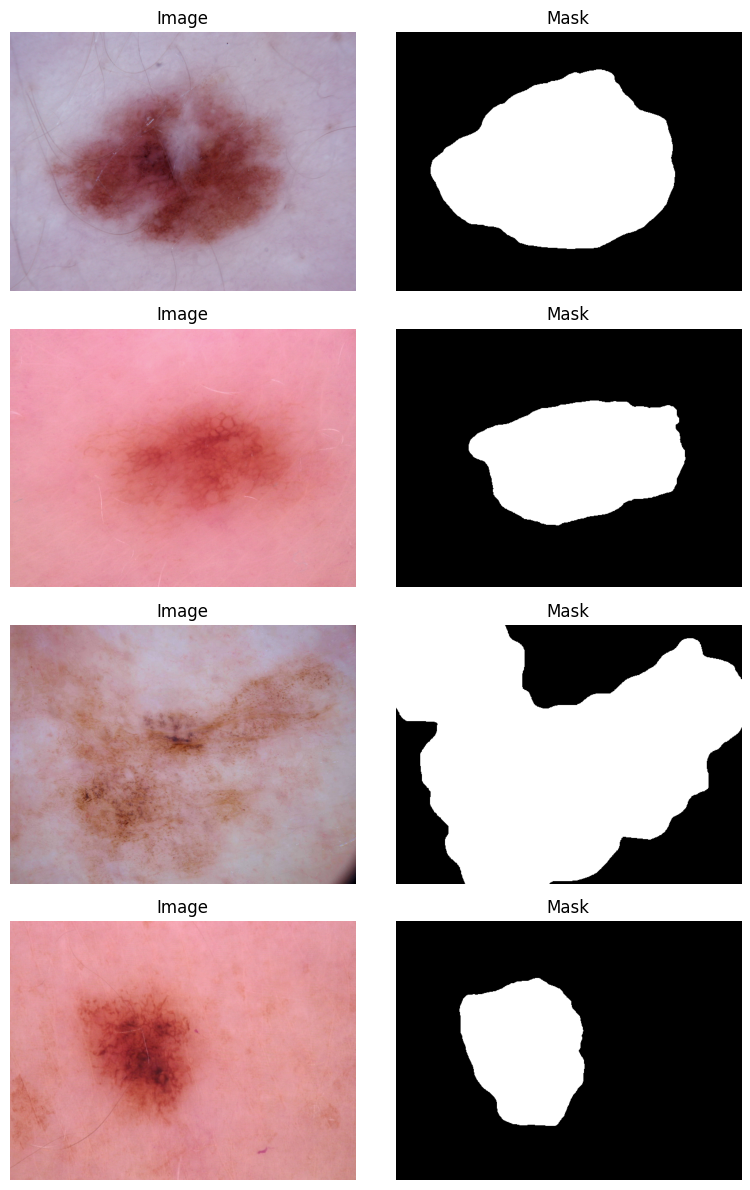

In [ ]:
def show_samples(pairs, n=4):
    fig, axes = plt.subplots(n, 2, figsize=(8, n * 3))
    idxs = random.sample(range(len(pairs)), n)

    for i, idx in enumerate(idxs):
        img = np.array(Image.open(pairs[idx][0]).convert("RGB"))
        mask = np.array(Image.open(pairs[idx][1]).convert("L"))

        axes[i, 0].imshow(img)
        axes[i, 0].set_title("Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(mask, cmap="gray")
        axes[i, 1].set_title("Mask")
        axes[i, 1].axis("off")

    plt.tight_layout()
    plt.show()

show_samples(pairs)

---
## 🏗️ Part 3: Model Setup

### Cell 7 — Configuration

In [ ]:
# ── Configuration ────────────────────────────────────────────────────
IMG_SIZE = 256          # Image size (256x256 for T4 GPU)
BATCH_SIZE = 20          # Batch size (Attention U-Net is larger than regular U-Net)
NUM_EPOCHS = 20         # Training epochs
LR = 1e-4               # Learning rate
NUM_WORKERS = 2         # DataLoader workers

# Model selection (choose one)
MODEL_TYPE = "AttU_Net"  # Options: "U_Net", "R2U_Net", "AttU_Net", "R2AttU_Net"
# ─────────────────────────────────────────────────────────────────────

# Split dataset
train_pairs, val_pairs = train_test_split(pairs, test_size=0.15, random_state=SEED)

print(f"Configuration:")
print(f"  Model: {MODEL_TYPE}")
print(f"  Image Size: {IMG_SIZE}x{IMG_SIZE}")
print(f"  Batch Size: {BATCH_SIZE}")
print(f"  Epochs: {NUM_EPOCHS}")
print(f"  Learning Rate: {LR}")
print(f"\nDataset Split:")
print(f"  Train: {len(train_pairs)}")
print(f"  Val  : {len(val_pairs)}")

Configuration:
  Model: AttU_Net
  Image Size: 256x256
  Batch Size: 20
  Epochs: 20
  Learning Rate: 0.0001

Dataset Split:
  Train: 8512
  Val  : 1503


### Cell 8 — Dataset Class

In [ ]:
# Training augmentations
train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.4),
    A.GaussNoise(p=0.2),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

# Validation augmentations
val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

class HAMDataset(Dataset):
    def __init__(self, pairs, transform=None):
        self.pairs = pairs
        self.transform = transform

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]

        image = np.array(Image.open(img_path).convert("RGB"))
        mask = np.array(Image.open(mask_path).convert("L"))

        # Binarize mask
        mask = (mask > 127).astype(np.float32)

        if self.transform:
            aug = self.transform(image=image, mask=mask)
            image = aug["image"]
            mask = aug["mask"].unsqueeze(0)  # (1, H, W)

        return image, mask

# Create datasets
train_ds = HAMDataset(train_pairs, transform=train_transform)
val_ds = HAMDataset(val_pairs, transform=val_transform)

# Create dataloaders
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                         num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                       num_workers=NUM_WORKERS, pin_memory=True)

print(f"Train batches: {len(train_loader)}")
print(f"Val batches  : {len(val_loader)}")

Train batches: 426
Val batches  : 76


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


### Cell 9 — Build Attention U-Net Model

In [ ]:
# Create model based on selection
if MODEL_TYPE == "U_Net":
    model = U_Net(img_ch=3, output_ch=1)
elif MODEL_TYPE == "R2U_Net":
    model = R2U_Net(img_ch=3, output_ch=1, t=2)
elif MODEL_TYPE == "AttU_Net":
    model = AttU_Net(img_ch=3, output_ch=1)
elif MODEL_TYPE == "R2AttU_Net":
    model = R2AttU_Net(img_ch=3, output_ch=1, t=2)
else:
    raise ValueError(f"Unknown model type: {MODEL_TYPE}")

model = model.to(DEVICE)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\n{'='*60}")
print(f"Model: {MODEL_TYPE}")
print(f"{'='*60}")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"{'='*60}\n")


Model: AttU_Net
Total parameters: 34,878,573
Trainable parameters: 34,878,573



### Cell 10 — Loss Function & Metrics

In [ ]:
class DiceBCELoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)

        probs = torch.sigmoid(logits)
        inter = (probs * targets).sum(dim=(2, 3))
        dice_loss = 1 - (2 * inter + self.smooth) / (
            probs.sum(dim=(2, 3)) + targets.sum(dim=(2, 3)) + self.smooth
        )

        return bce_loss + dice_loss.mean()

def iou_score(logits, targets, threshold=0.5):
    preds = (torch.sigmoid(logits) > threshold).float()
    inter = (preds * targets).sum(dim=(2, 3))
    union = preds.sum(dim=(2, 3)) + targets.sum(dim=(2, 3)) - inter
    iou = (inter + 1e-6) / (union + 1e-6)
    return iou.mean().item()

def dice_score(logits, targets, threshold=0.5):
    preds = (torch.sigmoid(logits) > threshold).float()
    inter = (preds * targets).sum(dim=(2, 3))
    dice = (2 * inter + 1e-6) / (preds.sum(dim=(2, 3)) + targets.sum(dim=(2, 3)) + 1e-6)
    return dice.mean().item()

# Setup optimizer and scheduler
criterion = DiceBCELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)

print("✅ Loss function and optimizer configured")

✅ Loss function and optimizer configured


---
## 🚀 Part 4: Training

### Cell 11 — Training Loop

In [ ]:
history = {"train_loss": [], "val_loss": [], "val_iou": [], "val_dice": []}
best_iou = 0.0
best_model_path = f"/content/best_{MODEL_TYPE.lower()}_ham10000.pth"

print(f"\n{'='*70}")
print(f"Starting Training: {MODEL_TYPE}")
print(f"{'='*70}\n")

for epoch in range(1, NUM_EPOCHS + 1):
    # ── Training ─────────────────────────────────────────────────────
    model.train()
    train_loss = 0.0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch}/{NUM_EPOCHS} [Train]", leave=False)
    for images, masks in pbar:
        images, masks = images.to(DEVICE), masks.to(DEVICE)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        pbar.set_postfix({"loss": loss.item()})

    train_loss /= len(train_loader)

    # ── Validation ───────────────────────────────────────────────────
    model.eval()
    val_loss = 0.0
    val_iou = 0.0
    val_dice = 0.0

    with torch.no_grad():
        pbar = tqdm(val_loader, desc=f"Epoch {epoch}/{NUM_EPOCHS} [Val]", leave=False)
        for images, masks in pbar:
            images, masks = images.to(DEVICE), masks.to(DEVICE)

            logits = model(images)
            val_loss += criterion(logits, masks).item()
            val_iou += iou_score(logits, masks)
            val_dice += dice_score(logits, masks)

    val_loss /= len(val_loader)
    val_iou /= len(val_loader)
    val_dice /= len(val_loader)

    scheduler.step()

    # ── Save metrics ─────────────────────────────────────────────────
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_iou"].append(val_iou)
    history["val_dice"].append(val_dice)

    # ── Print progress ───────────────────────────────────────────────
    print(f"Epoch {epoch:02d} | "
          f"Loss: {train_loss:.4f} | "
          f"Val Loss: {val_loss:.4f} | "
          f"IoU: {val_iou:.4f} | "
          f"Dice: {val_dice:.4f}")

    # ── Save best model ──────────────────────────────────────────────
    if val_iou > best_iou:
        best_iou = val_iou
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_iou': best_iou,
            'best_dice': val_dice,
            'model_type': MODEL_TYPE
        }, best_model_path)
        print(f"  ✅ Best model saved (IoU: {best_iou:.4f})")

print(f"\n{'='*70}")
print(f"Training Complete!")
print(f"{'='*70}")
print(f"Best Val IoU: {best_iou:.4f}")
print(f"Model saved: {best_model_path}")


Starting Training: AttU_Net



Epoch 01 | Loss: 0.6829 | Val Loss: 0.4859 | IoU: 0.7881 | Dice: 0.8685
  ✅ Best model saved (IoU: 0.7881)


Epoch 02 | Loss: 0.4460 | Val Loss: 0.3782 | IoU: 0.8115 | Dice: 0.8818
  ✅ Best model saved (IoU: 0.8115)


Epoch 03 | Loss: 0.3504 | Val Loss: 0.2947 | IoU: 0.8454 | Dice: 0.9072
  ✅ Best model saved (IoU: 0.8454)


Epoch 04 | Loss: 0.3022 | Val Loss: 0.2960 | IoU: 0.8292 | Dice: 0.8956


...

Epoch 16 | Loss: 0.1983 | Val Loss: 0.1829 | IoU: 0.8830 | Dice: 0.9318
  ✅ Best model saved (IoU: 0.8830)


Epoch 17 | Loss: 0.1945 | Val Loss: 0.1817 | IoU: 0.8819 | Dice: 0.9310


Epoch 18 | Loss: 0.1923 | Val Loss: 0.1773 | IoU: 0.8852 | Dice: 0.9330
  ✅ Best model saved (IoU: 0.8852)


Epoch 19 | Loss: 0.1906 | Val Loss: 0.1769 | IoU: 0.8856 | Dice: 0.9333
  ✅ Best model saved (IoU: 0.8856)


Epoch 20 | Loss: 0.1896 | Val Loss: 0.1766 | IoU: 0.8857 | Dice: 0.9333
  ✅ Best model saved (IoU: 0.8857)

Training Complete!
Best Val IoU: 0.8857
Model saved: /content/best_attu_net_ham10000.pth


### Cell 12 — Plot Training Curves

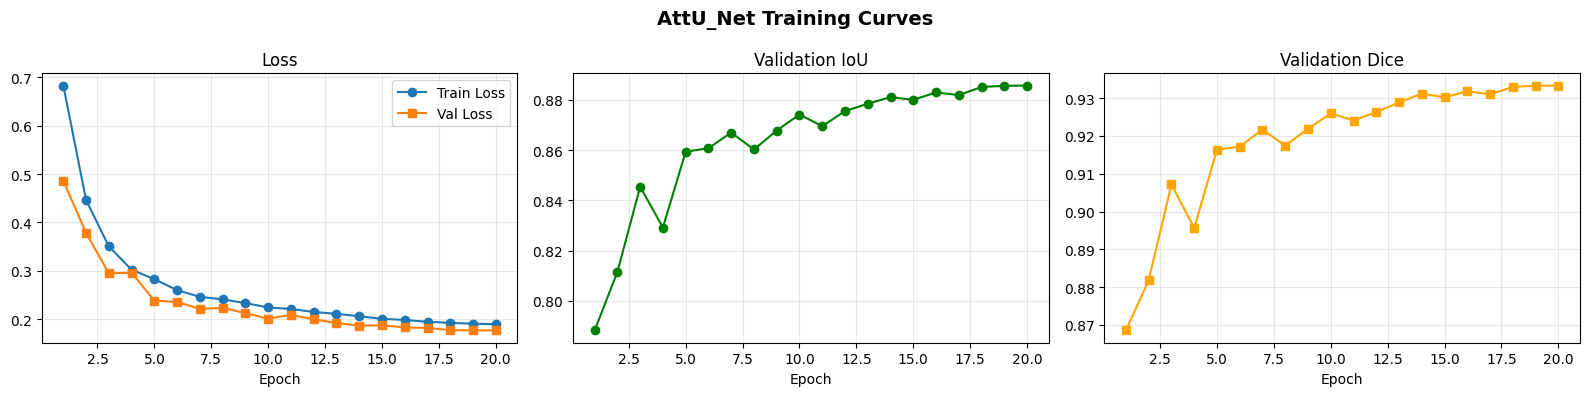

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
epochs = range(1, len(history["train_loss"]) + 1)

# Loss
axes[0].plot(epochs, history["train_loss"], label="Train Loss", marker='o')
axes[0].plot(epochs, history["val_loss"], label="Val Loss", marker='s')
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

# IoU
axes[1].plot(epochs, history["val_iou"], color="green", marker='o')
axes[1].set_title("Validation IoU")
axes[1].set_xlabel("Epoch")
axes[1].grid(alpha=0.3)

# Dice
axes[2].plot(epochs, history["val_dice"], color="orange", marker='s')
axes[2].set_title("Validation Dice")
axes[2].set_xlabel("Epoch")
axes[2].grid(alpha=0.3)

plt.suptitle(f"{MODEL_TYPE} Training Curves", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 🔍 Part 5: Inference & Visualization

### Cell 13 — Load Best Model & Visualize Results

✅ Loaded best model from epoch 20
   Best IoU: 0.8857
   Best Dice: 0.9333


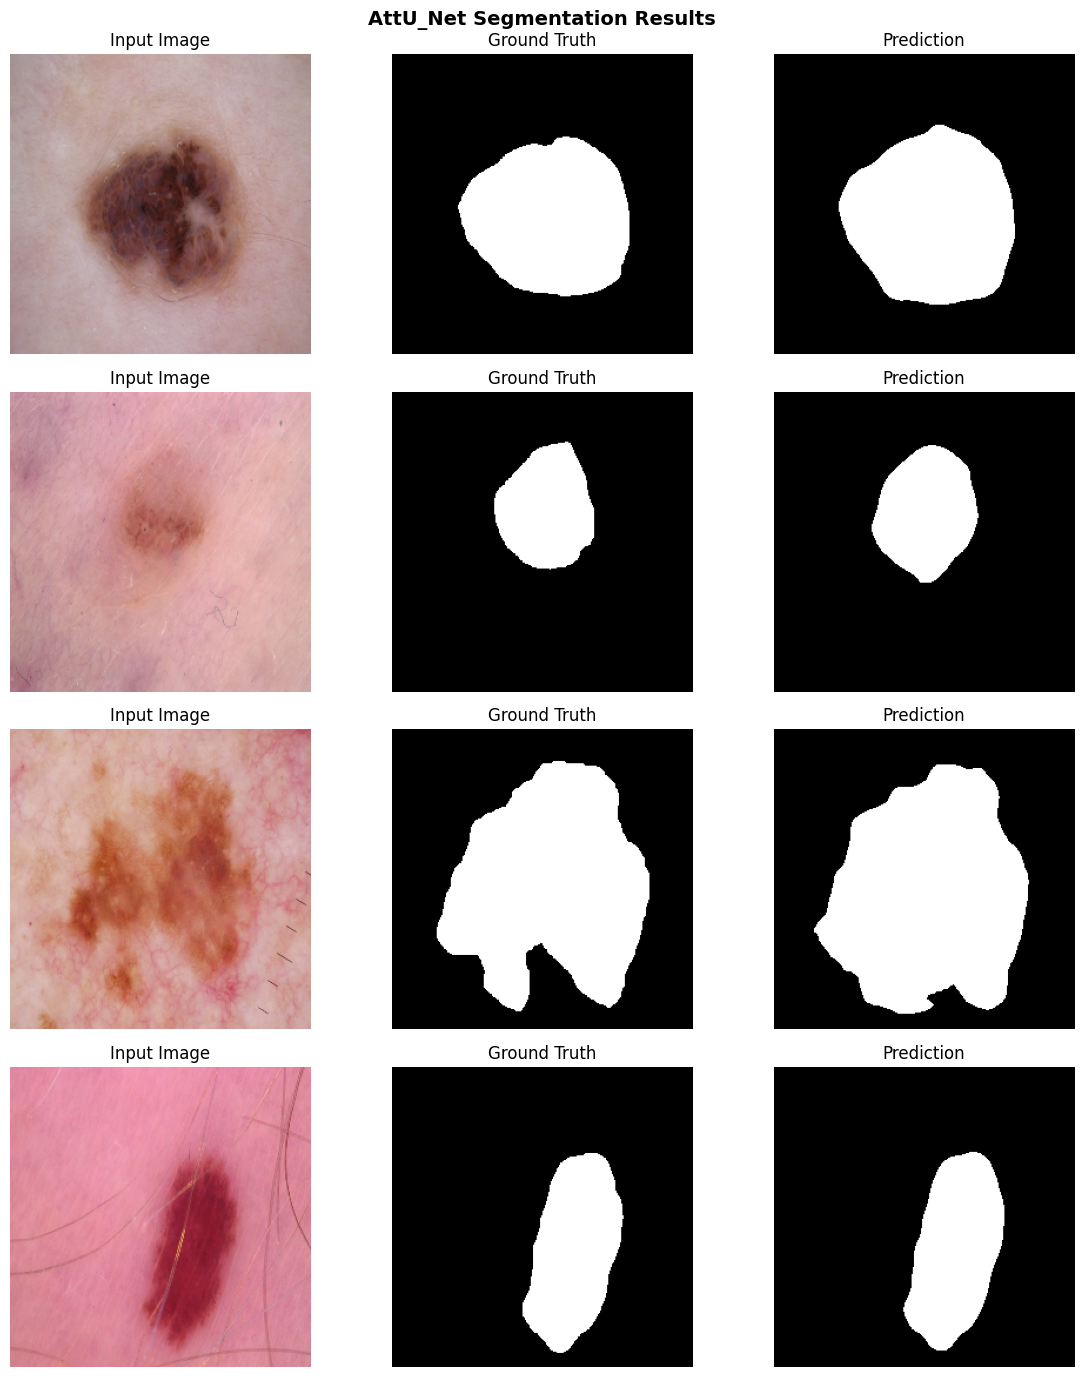

In [ ]:
# Load best model
checkpoint = torch.load(best_model_path)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

print(f"✅ Loaded best model from epoch {checkpoint['epoch']}")
print(f"   Best IoU: {checkpoint['best_iou']:.4f}")
print(f"   Best Dice: {checkpoint['best_dice']:.4f}")

# Visualize predictions
fig, axes = plt.subplots(4, 3, figsize=(12, 14))
sample_indices = random.sample(range(len(val_ds)), 4)

for row, idx in enumerate(sample_indices):
    image_t, mask_t = val_ds[idx]

    with torch.no_grad():
        logit = model(image_t.unsqueeze(0).to(DEVICE))
        pred = torch.sigmoid(logit).squeeze().cpu().numpy()
        pred_binary = (pred > 0.5).astype(np.uint8)

    # Denormalize image
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img_display = image_t.permute(1, 2, 0).numpy() * std + mean
    img_display = np.clip(img_display, 0, 1)
    mask_display = mask_t.squeeze().numpy()

    # Plot
    axes[row, 0].imshow(img_display)
    axes[row, 0].set_title("Input Image")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(mask_display, cmap="gray")
    axes[row, 1].set_title("Ground Truth")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(pred_binary, cmap="gray")
    axes[row, 2].set_title("Prediction")
    axes[row, 2].axis("off")

plt.suptitle(f"{MODEL_TYPE} Segmentation Results", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### Cell 14 — Save & Download Model

In [ ]:
from google.colab import files

# Download best model
files.download(best_model_path)

print(f"✅ Model downloaded: {best_model_path}")
print(f"\nModel info:")
print(f"  Type: {MODEL_TYPE}")
print(f"  Best IoU: {checkpoint['best_iou']:.4f}")
print(f"  Best Dice: {checkpoint['best_dice']:.4f}")
print(f"  Epoch: {checkpoint['epoch']}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Model downloaded: /content/best_attu_net_ham10000.pth

Model info:
  Type: AttU_Net
  Best IoU: 0.8857
  Best Dice: 0.9333
  Epoch: 20


---

## 📊 Model Comparison

You trained: **{MODEL_TYPE}**

### Available Models:

| Model | Description | Parameters | Performance |
|-------|-------------|------------|-------------|
| **U_Net** | Standard U-Net | ~31M | Baseline |
| **R2U_Net** | U-Net with Recurrent blocks | ~40M | Better temporal features |
| **AttU_Net** | U-Net with Attention Gates | ~34M | ⭐ Focus on lesion |
| **R2AttU_Net** | Recurrent + Attention | ~45M | Best (but slowest) |

### Expected Results:
- **U_Net**: IoU ~0.85-0.88
- **AttU_Net**: IoU ~0.87-0.90 ⭐
- **R2AttU_Net**: IoU ~0.88-0.91 (best)

### To Try Another Model:
Change `MODEL_TYPE` in Cell 7 and re-run from there!

---

## 🎉 Congratulations!

You've successfully trained **Attention U-Net** for skin lesion segmentation!

**Next steps:**
1. Compare with regular U-Net (set `MODEL_TYPE = "U_Net"`)
2. Try R2AttU_Net for even better results
3. Create a web app with Gradio (see previous notebooks)
4. Deploy to Hugging Face Spaces

**Your model is now ready for deployment!** 🚀